In [14]:
import numpy as np
import pandas as pd
import yfinance as yf

from arch import arch_model

# S&P 500 데이터
sp = yf.download("^GSPC", period="5y", auto_adjust=True)

sp_close = sp["Close"]

# 로그수익률 (% 단위)
returns = (np.log(sp_close / sp_close.shift(1)).dropna() * 100)["^GSPC"]

# GARCH(1,1)
model = arch_model(returns, mean="Constant", vol="GARCH", p=1, q=1, dist="normal")

# 학습
fitted = model.fit(disp="off")

# 결과
print(fitted.summary())

[*********************100%***********************]  1 of 1 completed

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                  ^GSPC   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -1747.40
Distribution:                  Normal   AIC:                           3502.81
Method:            Maximum Likelihood   BIC:                           3523.34
                                        No. Observations:                 1254
Date:                Sun, Nov 22 2026   Df Residuals:                     1253
Time:                        15:20:13   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.0617  2.451e-02      2.518  1.181e-02 [1.367e-0

In [15]:
params = fitted.params

omega = params["omega"]
alpha = params["alpha[1]"]
beta = params["beta[1]"]

print(f"omega: {omega:.6f}")
print(f"alpha: {alpha:.6f}")
print(f"beta : {beta:.6f}")

print(f"alpha + beta: {alpha + beta:.6f}")

omega: 0.035648
alpha: 0.104644
beta : 0.865539
alpha + beta: 0.970183


In [16]:
vix = yf.download("^VIX", period="5y", auto_adjust=True)
vix_close = vix["Close"]["^VIX"]

vix_daily_variance = (vix_close**2) / 252

[*********************100%***********************]  1 of 1 completed


In [17]:
garch_variance = fitted.conditional_volatility**2
premium = vix_daily_variance - garch_variance

In [18]:
rv = returns.rolling(21).var()

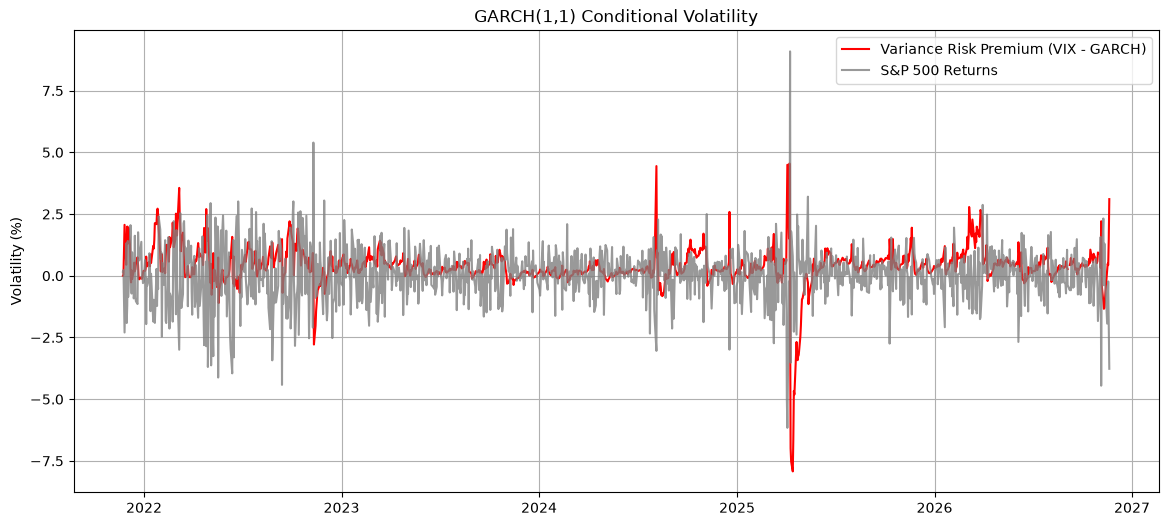

In [19]:
import matplotlib.pyplot as plt

# 조건부 변동성 (%)
conditional_vol = fitted.conditional_volatility

plt.figure(figsize=(14, 6))

# plt.plot(conditional_vol, label="GARCH Conditional Volatility")
# plt.plot(vix_daily_variance, label="VIX Daily Variance", color="orange")
# plt.plot(rv, label="Realized Variance (21-day rolling)", color="green")
plt.plot(premium, label="Variance Risk Premium (VIX - GARCH)", color="red")
plt.plot(returns, label="S&P 500 Returns", color="gray", alpha=0.8)

plt.title("GARCH(1,1) Conditional Volatility")
plt.ylabel("Volatility (%)")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
future_rv = returns.pow(2).rolling(21).sum().shift(-21)

result = pd.concat([premium.rename("premium"), future_rv], axis=1).dropna()

print(result.corr())

          premium     ^GSPC
premium  1.000000  0.120019
^GSPC    0.120019  1.000000


In [21]:
future_rv = returns.pow(2).rolling(21).sum().shift(-21)

# 데이터 정렬 및 결측치 제거
result = pd.concat(
    [
        premium.rename("premium"),
        garch_variance.rename("garch_variance"),
        future_rv.rename("future_rv"),
    ],
    axis=1,
).dropna()

# 상관관계 분석
print("Correlation Matrix")
print(result.corr())

# VRP와 미래 실현분산의 상관계수
print("\nPremium vs Future RV:", result["premium"].corr(result["future_rv"]))

Correlation Matrix
                 premium  garch_variance  future_rv
premium         1.000000       -0.512464   0.120019
garch_variance -0.512464        1.000000   0.367258
future_rv       0.120019        0.367258   1.000000

Premium vs Future RV: 0.12001850448724982


In [22]:
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error
import numpy as np

result_sampled = result.iloc[::21].copy()

# 설명변수
X_a = result_sampled[["garch_variance"]]
X_b = result_sampled[["garch_variance", "premium"]]

y = result_sampled["future_rv"]

# 시간순 80:20 분할
split = int(len(result_sampled) * 0.8)

X_a_train, X_a_test = X_a.iloc[:split], X_a.iloc[split:]
X_b_train, X_b_test = X_b.iloc[:split], X_b.iloc[split:]

y_train, y_test = y.iloc[:split], y.iloc[split:]

# 상수항 추가
X_a_train = sm.add_constant(X_a_train)
X_a_test = sm.add_constant(X_a_test)

X_b_train = sm.add_constant(X_b_train)
X_b_test = sm.add_constant(X_b_test)

# 모델 학습
model_a = sm.OLS(y_train, X_a_train).fit()
model_b = sm.OLS(y_train, X_b_train).fit()

# 예측
pred_a = model_a.predict(X_a_test)
pred_b = model_b.predict(X_b_test)

# 성능 비교
rmse_a = np.sqrt(mean_squared_error(y_test, pred_a))
rmse_b = np.sqrt(mean_squared_error(y_test, pred_b))

print("Model A: GARCH")
print(model_a.summary())

print("\nModel B: GARCH + Premium")
print(model_b.summary())

print("\nRMSE Comparison")
print("GARCH:", rmse_a)
print("GARCH + Premium:", rmse_b)

Model A: GARCH
                            OLS Regression Results                            
Dep. Variable:              future_rv   R-squared:                       0.195
Model:                            OLS   Adj. R-squared:                  0.177
Method:                 Least Squares   F-statistic:                     10.88
Date:                Sun, 22 Nov 2026   Prob (F-statistic):            0.00190
Time:                        15:20:14   Log-Likelihood:                -222.37
No. Observations:                  47   AIC:                             448.7
Df Residuals:                      45   BIC:                             452.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              6.2919    

In [23]:
from sklearn.metrics import mean_squared_error
import statsmodels.api as sm
import numpy as np
import pandas as pd

offset_results = []

for offset in range(21):
    sampled = result.iloc[offset::21].copy()

    X_a = sampled[["garch_variance"]]
    X_b = sampled[["garch_variance", "premium"]]
    y = sampled["future_rv"]

    split = int(len(sampled) * 0.8)

    Xa_train, Xa_test = X_a.iloc[:split], X_a.iloc[split:]
    Xb_train, Xb_test = X_b.iloc[:split], X_b.iloc[split:]
    y_train, y_test = y.iloc[:split], y.iloc[split:]

    Xa_train = sm.add_constant(Xa_train)
    Xa_test = sm.add_constant(Xa_test)

    Xb_train = sm.add_constant(Xb_train)
    Xb_test = sm.add_constant(Xb_test)

    model_a = sm.OLS(y_train, Xa_train).fit()
    model_b = sm.OLS(y_train, Xb_train).fit()

    pred_a = model_a.predict(Xa_test)
    pred_b = model_b.predict(Xb_test)

    rmse_a = np.sqrt(mean_squared_error(y_test, pred_a))
    rmse_b = np.sqrt(mean_squared_error(y_test, pred_b))

    offset_results.append(
        {
            "offset": offset,
            "n": len(sampled),
            "RMSE_GARCH": rmse_a,
            "RMSE_GARCH_Premium": rmse_b,
            "improvement_%": (rmse_a - rmse_b) / rmse_a * 100,
        }
    )

offset_df = pd.DataFrame(offset_results)

print(offset_df.to_string(index=False))
print("\nMean improvement:")
print(offset_df["improvement_%"].mean())

 offset  n  RMSE_GARCH  RMSE_GARCH_Premium  improvement_%
      0 59   11.488896           10.029511      12.702569
      1 59   11.310016           10.396581       8.076338
      2 59    9.200937           17.838345     -93.875305
      3 59   11.224022            8.979856      19.994317
      4 59   11.222174           10.966025       2.282529
      5 59   12.073904           11.071938       8.298613
      6 59   11.545215           10.618425       8.027482
      7 59   13.001654           11.215491      13.737970
      8 59   12.846827           10.547779      17.895846
      9 59   12.650432           11.237562      11.168548
     10 59   12.788992           11.713901       8.406379
     11 59   12.982671           11.123277      14.322122
     12 59   12.230671           12.963620      -5.992719
     13 59   13.177686           15.502663     -17.643292
     14 59   15.423082           16.796538      -8.905200
     15 58   11.700687           13.138605     -12.289179
     16 58   1

count    1233.000000
mean        0.393119
std         0.794929
min        -7.925410
25%         0.134636
50%         0.362662
75%         0.632891
max         4.548677
Name: premium, dtype: float64

Quantiles:
0.00   -7.925410
0.01   -2.330148
0.05   -0.276625
0.50    0.362662
0.95    1.485690
0.99    2.432870
1.00    4.548677
Name: premium, dtype: float64


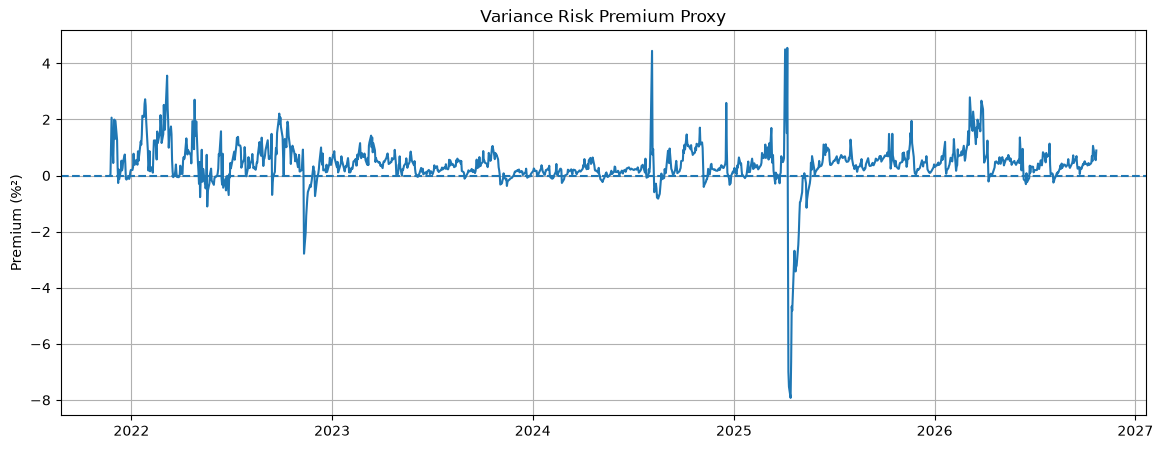

In [24]:
# Premium 분포 확인
print(result["premium"].describe())

# 상위 1%, 하위 1% 확인
print("\nQuantiles:")
print(result["premium"].quantile([0, 0.01, 0.05, 0.5, 0.95, 0.99, 1]))

# Premium 시계열
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(result["premium"])
plt.axhline(0, linestyle="--")
plt.title("Variance Risk Premium Proxy")
plt.ylabel("Premium (%²)")
plt.grid(True)
plt.show()

In [25]:
from garch_model import (
    create_garch_premium_model,
    make_future_variance,
    make_garch_premium_features,
    walk_forward_garch_premium_predict,
)

# 회귀 입력과 미래 실현분산 타깃을 날짜 기준으로 결합
regression_features = make_garch_premium_features(
    garch_variance,
    premium,
)
future_variance = make_future_variance(returns, horizon=21)

regression_data = pd.concat(
    [regression_features, future_variance],
    axis=1,
).dropna()

X = regression_data[["garch_variance", "premium"]]
y = regression_data["future_variance"]

# 최신 시점의 회귀 예측
latest_model = create_garch_premium_model(alpha=10.0)
latest_model.fit(X, y)
latest_prediction = latest_model.predict(X.iloc[[-1]])

print("Latest predicted 21-day variance:", latest_prediction[0])

# 과거 정보만 사용하는 워크포워드 예측
walk_forward_prediction = walk_forward_garch_premium_predict(
    X,
    y,
    train_size=756,
    test_size=63,
    alpha=10.0,
)

walk_forward_result = pd.concat(
    [
        y.rename("future_variance"),
        walk_forward_prediction,
    ],
    axis=1,
).dropna()

print(walk_forward_result.tail())

Latest predicted 21-day variance: 22.573781249754582
            future_variance  predicted_future_variance
Date                                                  
2026-10-16        40.746334                  23.033636
2026-10-19        41.642747                  19.998893
2026-10-20        41.615460                  18.006647
2026-10-21        45.439539                  16.962631
2026-10-22        58.168531                  21.154911


In [26]:
from garch_model import (
    make_garch_auto_leverage_results,
    calculate_auto_leverage_performance,
    optimize_garch_leverage_parameters,
)

sp500_close = sp["Close"]["^GSPC"]
sp500_return = sp500_close.pct_change()

TARGET_VOLATILITY = 0.25
MIN_LEVERAGE = 0.5
MAX_LEVERAGE = 2.0

optimized_parameters = optimize_garch_leverage_parameters(
    sp500_return,
    walk_forward_prediction,
    target_volatility=TARGET_VOLATILITY,
    target_sharpe=None,
    min_leverage=MIN_LEVERAGE,
    max_leverage=MAX_LEVERAGE,
    seed=42,
)

print("Optimized parameters:", optimized_parameters)

auto_leverage_results = make_garch_auto_leverage_results(
    sp500_return,
    walk_forward_prediction,
    target_volatility=optimized_parameters["target_volatility"],
    alpha=optimized_parameters["alpha"],
    min_leverage=MIN_LEVERAGE,
    max_leverage=MAX_LEVERAGE,
    ema_span=optimized_parameters["ema_span"],
)

print(calculate_auto_leverage_performance(auto_leverage_results["strategy_return"]))

ImportError: cannot import name 'make_garch_auto_leverage_results' from 'garch_model' (c:\Users\freesia\Documents\labs\auto-leverage\garch_model.py)